# Linesearch Implicit NN From LJ Data

This notebook generates target geometries with `LJFF`, then trains `NNPotentialFF` with `LinesearchImplicitMultipleSystemOptimizer`. This optimizer avoids exact line minimization, which can be awkward for neural-network potentials.


In [1]:
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..', '..', '..')))

import copy
import torch
import numpy as np
import matplotlib.pyplot as plt

from geomatry.opt_Energy_approximated.optimizer import ExactLineSearchDirectionalImplicitMultipleSystemOptimizer as LinesearchImplicitMultipleSystemOptimizer
from geomatry.opt.loss import rmsd_loss
from geomatry.ff.graph import get_given_graph_builder
from geomatry.ff.springs import LJFF, _random_lj_systems, _random_lj_ff_param
from geomatry.ff.NN import NNPotentialFF


In [2]:
def min_pair_distance(Ra: torch.Tensor) -> float:
    Ra = Ra.detach()
    dmat = torch.cdist(Ra, Ra)
    return float(torch.min(dmat + torch.eye(Ra.shape[0], device=Ra.device) * 1e6))


In [3]:
systemN = 40
N = 10
N_pairs = 30
max_Za = 1
fixed_atom_indices = [0, 1]

Ras, Zas, idx_is, idx_js = _random_lj_systems(systemN, N, N_pairs, max_Za, start_Za=1)
epsilon, sigma = _random_lj_ff_param(max_Za, epsilon_range=(0.7, 2.0), sigma_range=(0.9, 1.1))

target_ff = LJFF(max_Za)
target_ff.reset_parameters(epsilon, sigma)
params_star = copy.deepcopy(target_ff.state_dict())

graph_builders = [get_given_graph_builder(idx_i, idx_j) for idx_i, idx_j in zip(idx_is, idx_js)]

print('sample target epsilon', epsilon[1:, 1:].mean().item())
print('sample target sigma', sigma[1:, 1:].mean().item())
print('sample min distances', [min_pair_distance(Ra) for Ra in Ras[:3]])


sample target epsilon 0.9775277666466575
sample target sigma 1.0840136625700874
sample min distances [0.7547813878852023, 0.9107229951109242, 0.949132262575202]


In [4]:
# Use LJFF only to generate target optimized geometries.
target_optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, target_ff, rmsd_loss,
    params_star=params_star,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
Ra_star_list = target_optimizer.Ra_stars

from geomatry.opt_Energy_approximated.calculator import get_ase_atoms

with torch.no_grad():
    target_energies = torch.stack([
        target_ff.get_E(Ra_star, Za, *graph_builder(get_ase_atoms(Ra_star, Za))).detach()
        for Ra_star, Za, graph_builder in zip(Ra_star_list, Zas, graph_builders)
    ]).float()

# Train the NN force field with Linesearch implicit gradients.
nn_ff = NNPotentialFF(max_Za, hidden_dim=24)
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
params_0 = copy.deepcopy(nn_ff.state_dict())

print('target geometries', len(Ra_star_list))
print('NN parameter tensors', len(params_0))


target geometries 40
NN parameter tensors 18


In [5]:
from tqdm.auto import tqdm

def sample_pretrain_batch(batch_size):
    batch_size = min(batch_size, len(Ra_star_list))
    return torch.randperm(len(Ra_star_list))[:batch_size].tolist()

def predict_target_geometry_energies(ff, batch_indices):
    return torch.stack([
        ff.get_E(Ra_star_list[i].float(), Zas[i].long(), *graph_builders[i](get_ase_atoms(Ra_star_list[i], Zas[i])))
        for i in batch_indices
    ])

def force_square_loss_at_target_geometries(ff, batch_indices):
    force_terms = []
    for i in batch_indices:
        Ra_eval = Ra_star_list[i].detach().float().requires_grad_(True)
        E = ff.get_E(Ra_eval, Zas[i].long(), *graph_builders[i](get_ase_atoms(Ra_eval.detach(), Zas[i])))
        Fa = ff.get_Fa(E, Ra_eval)
        if fixed_atom_indices is not None:
            Fa = Fa.clone()
            Fa[fixed_atom_indices, :] = 0
        force_terms.append(torch.mean(Fa ** 2))
    return torch.stack(force_terms).mean()

pretrain_optimizer = torch.optim.Adam(nn_ff.parameters(), lr=1e-3, weight_decay=1e-6)
pretrain_epochs = 501
pretrain_print_period = 100
pretrain_batch_size = 8
force_loss_weight = 1.0
pbar = tqdm(range(pretrain_epochs), desc='energy+force pretrain')
for epoch in pbar:
    batch_indices = sample_pretrain_batch(pretrain_batch_size)
    batch_target_energies = target_energies[batch_indices]

    pretrain_optimizer.zero_grad()
    y_pred = predict_target_geometry_energies(nn_ff, batch_indices)
    energy_loss = torch.mean((y_pred - batch_target_energies) ** 2)
    force_loss = force_square_loss_at_target_geometries(nn_ff, batch_indices)
    loss = energy_loss + force_loss_weight * force_loss
    loss.backward()
    pretrain_optimizer.step()

    errors = predict_target_geometry_energies(nn_ff, batch_indices).detach() - batch_target_energies
    rmse = torch.sqrt(torch.mean(errors ** 2)).item()
    mae = torch.mean(torch.abs(errors)).item()
    force_rmse = torch.sqrt(force_square_loss_at_target_geometries(nn_ff, batch_indices).detach()).item()
    pbar.set_postfix(
        batch=pretrain_batch_size,
        loss=f'{loss.item():.6e}',
        energy=f'{energy_loss.item():.6e}',
        force=f'{force_loss.item():.6e}',
        rmse=f'{rmse:.6f}',
        force_rmse=f'{force_rmse:.6f}',
    )

    if epoch % pretrain_print_period == 0 or epoch == pretrain_epochs - 1:
        tqdm.write(
            f'Pretrain {epoch}, batch={pretrain_batch_size}, loss={loss.item():.6e}, '
            f'energy_loss={energy_loss.item():.6e}, force_loss={force_loss.item():.6e}, '
            f'rmse={rmse:.6f}, mae={mae:.6f}, force_rmse={force_rmse:.6f}'
        )

params_pretrained = copy.deepcopy(nn_ff.state_dict())
print('energy+force pretrain complete')


energy+force pretrain:   0%|          | 0/501 [00:00<?, ?it/s]

Pretrain 0, batch=8, loss=3.413584e+03, energy_loss=3.409567e+03, force_loss=4.016566e+00, rmse=54.818842, mae=54.608162, force_rmse=1.822350
Pretrain 100, batch=8, loss=5.747811e+01, energy_loss=5.692770e+01, force_loss=5.504075e-01, rmse=7.559183, mae=6.778468, force_rmse=0.732980
Pretrain 200, batch=8, loss=2.002229e+01, energy_loss=1.956987e+01, force_loss=4.524229e-01, rmse=4.306263, mae=3.910321, force_rmse=0.682738
Pretrain 300, batch=8, loss=3.481230e+01, energy_loss=3.442355e+01, force_loss=3.887484e-01, rmse=5.841725, mae=4.420176, force_rmse=0.629522
Pretrain 400, batch=8, loss=3.655275e+01, energy_loss=3.617772e+01, force_loss=3.750292e-01, rmse=6.064753, mae=5.151919, force_rmse=0.596944
Pretrain 500, batch=8, loss=2.432904e+01, energy_loss=2.408437e+01, force_loss=2.446709e-01, rmse=4.492220, mae=4.083931, force_rmse=0.512833
energy+force pretrain complete


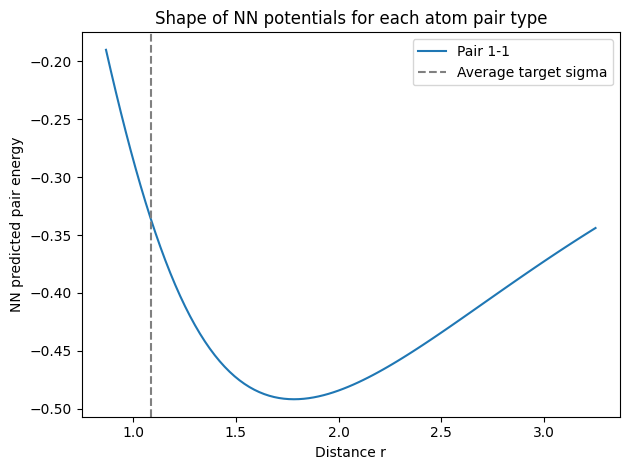

In [6]:

r_vals = torch.linspace(sigma[1:, 1:].mean().item()*0.8, sigma[1:, 1:].mean().item()*3, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.axvline(x=sigma[1:, 1:].mean().item(), color='gray', linestyle='--', label='Average target sigma')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()



  0%|          | 0/401 [00:04<?, ?it/s, alpha_star=1.0528e+00, min_epsilon=N/A, total_scale=2.382136e+00]

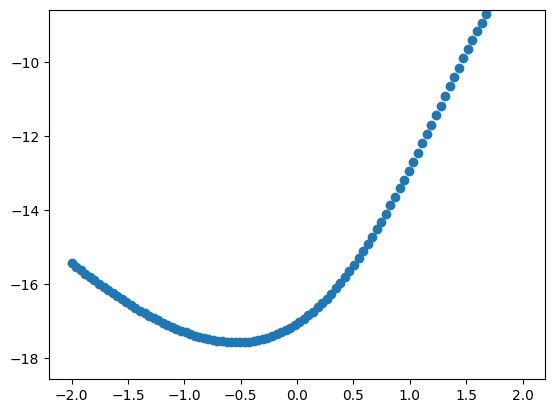

  0%|          | 1/401 [00:04<31:59,  4.80s/it, alpha_star=1.0528e+00, min_epsilon=N/A, total_scale=2.382136e+00]

1.0527980670955661
Iteration 0, alpha_star=1.0528e+00, total_scale=2.382136e+00


 20%|█▉        | 80/401 [06:04<27:23,  5.12s/it, alpha_star=5.3405e-01, min_epsilon=N/A, total_scale=1.339207e+00]

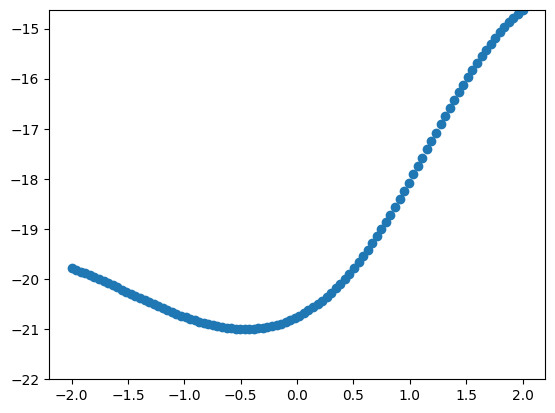

 20%|██        | 81/401 [06:04<29:02,  5.45s/it, alpha_star=5.3405e-01, min_epsilon=N/A, total_scale=1.339207e+00]

0.5340504460462328
Iteration 80, alpha_star=5.3405e-01, total_scale=1.339207e+00


 40%|███▉      | 160/401 [17:44<29:24,  7.32s/it, alpha_star=1.3275e-01, min_epsilon=N/A, total_scale=3.146735e-01]  

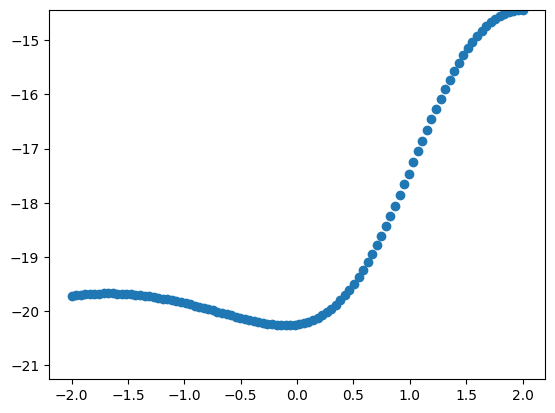

 40%|████      | 161/401 [17:45<29:13,  7.31s/it, alpha_star=1.3275e-01, min_epsilon=N/A, total_scale=3.146735e-01]

0.13274622274744355
Iteration 160, alpha_star=1.3275e-01, total_scale=3.146735e-01


 60%|█████▉    | 240/401 [26:34<17:08,  6.39s/it, alpha_star=8.1756e-02, min_epsilon=N/A, total_scale=1.800741e-01]

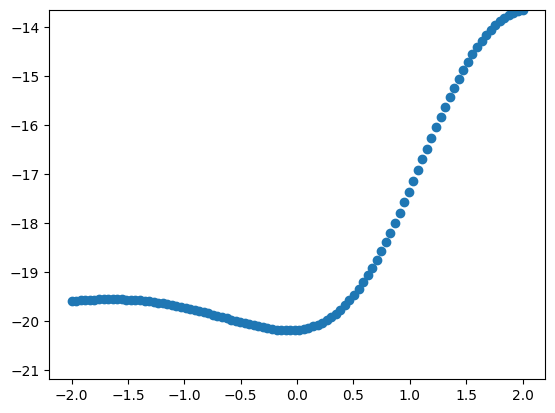

 60%|██████    | 241/401 [26:34<16:17,  6.11s/it, alpha_star=8.1756e-02, min_epsilon=N/A, total_scale=1.800741e-01]

0.08175551458784606
Iteration 240, alpha_star=8.1756e-02, total_scale=1.800741e-01


 80%|███████▉  | 320/401 [34:01<06:49,  5.06s/it, alpha_star=6.2393e-02, min_epsilon=N/A, total_scale=1.282792e-01]

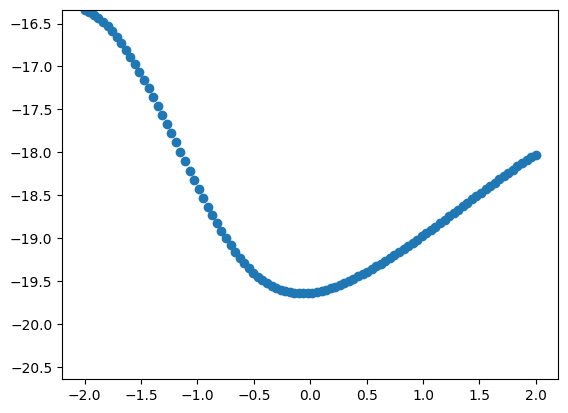

 80%|████████  | 321/401 [34:01<06:51,  5.14s/it, alpha_star=6.2393e-02, min_epsilon=N/A, total_scale=1.282792e-01]

0.06239315417916794
Iteration 320, alpha_star=6.2393e-02, total_scale=1.282792e-01


100%|█████████▉| 400/401 [41:39<00:05,  5.94s/it, alpha_star=9.9317e-02, min_epsilon=N/A, total_scale=1.459133e-01]

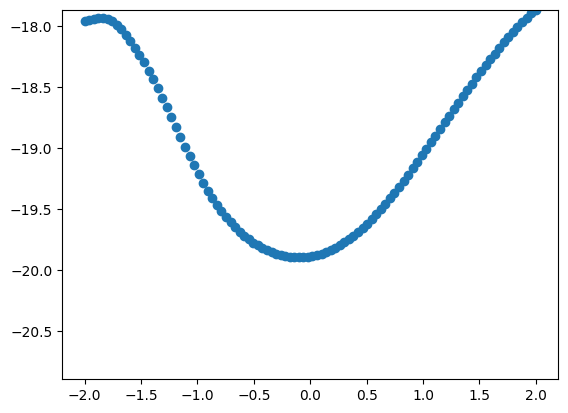

100%|██████████| 401/401 [41:40<00:00,  6.23s/it, alpha_star=9.9317e-02, min_epsilon=N/A, total_scale=1.459133e-01]

0.09931729623527134
Iteration 400, alpha_star=9.9317e-02, total_scale=1.459133e-01
optimization complete


In [7]:
params_0 = copy.deepcopy(nn_ff.state_dict())
optimizer = LinesearchImplicitMultipleSystemOptimizer(
    Ras, Zas, graph_builders, nn_ff, rmsd_loss,
    Ra_stars=Ra_star_list,
    fixed_atom_indices=fixed_atom_indices,
    fmax=1e-5
)
#new_params = optimizer.optimize(params_pretrained, lr=1e-3, epoch=201, print_period=40, e_size=0.2, eN=9, sg=2,
#                                longRange=True, longRange_weight=1, R_far_value=3, batch_size=4)
new_params = optimizer.optimize(params_pretrained, lr=1e-3, epoch=401, print_period=80, e_size=0.2, eN=9, sg=2,
                                longRange=False, longRange_weight=0.0, R_far_value=5, batch_size=4)
print('optimization complete')


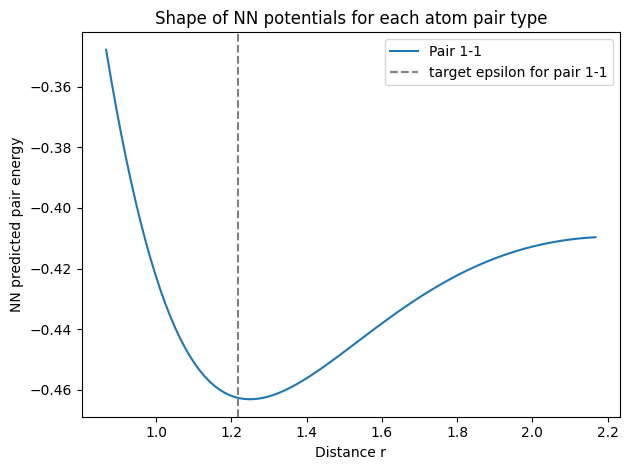

In [8]:
nn_ff.load_state_dict(new_params)

r_vals = torch.linspace(sigma[1:, 1:].mean().item()*0.8, sigma[1:, 1:].mean().item()*2, 100)
for i in range(1, max_Za + 1):
    for j in range(i, max_Za + 1):
        energies = [nn_ff.forward_single_pair(r, i, j).item() for r in r_vals]
        plt.plot(r_vals.numpy(), energies, label=f'Pair {i}-{j}')
plt.xlabel('Distance r')
plt.ylabel('NN predicted pair energy')
plt.axvline(sigma[i, j].item()*(2**(1/6)), color='gray', linestyle='--', label=f'target epsilon for pair {i}-{j}')
plt.title('Shape of NN potentials for each atom pair type')
plt.legend()
plt.tight_layout()
